In [ ]:

!pip install pandas numpy nltk scikit-learn matplotlib seaborn


In [ ]:

import pandas as pd
import numpy as np
import nltk

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, f1_score

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('punkt_tab')

print("NLP resources downloaded successfully!")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt_tab to /root/nltk_data...


NLP resources downloaded successfully!


[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [ ]:
import pandas
import numpy
import nltk
import sklearn
import matplotlib
import seaborn

print("All libraries are installed successfully!")

All libraries are installed successfully!


In [ ]:
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

print("Text preprocessing tools are ready!")

Text preprocessing tools are ready!


In [ ]:
def preprocess_text(text):
    # Convert text into lowercase
    text = text.lower()

    # Split text into words
    words = word_tokenize(text)

    # Remove stopwords and lemmatize words
    processed_words = []

    for word in words:
        if word.isalpha() and word not in stop_words:
            processed_words.append(lemmatizer.lemmatize(word))

    return " ".join(processed_words)


# Test our function
sample_text = "The students are studying different subjects and enjoying their classes."

result = preprocess_text(sample_text)

print("Original Text:", sample_text)
print("Processed Text:", result)

Original Text: The students are studying different subjects and enjoying their classes.
Processed Text: student studying different subject enjoying class


In [ ]:
data = {
    'text': [
        'I love this product',
        'This is amazing',
        'The service is excellent',
        'I am very happy',
        'The movie was fantastic',

        'I hate this product',
        'This is terrible',
        'The service is very bad',
        'I am disappointed',
        'The movie was boring',

        'The product is okay',
        'The service is average',
        'It is a normal day',
        'The movie was ordinary',
        'The experience was acceptable'
    ],

    'sentiment': [
        'positive', 'positive', 'positive', 'positive', 'positive',
        'negative', 'negative', 'negative', 'negative', 'negative',
        'neutral', 'neutral', 'neutral', 'neutral', 'neutral'
    ]
}

df = pd.DataFrame(data)

print(df)

                             text sentiment
0             I love this product  positive
1                 This is amazing  positive
2        The service is excellent  positive
3                 I am very happy  positive
4         The movie was fantastic  positive
5             I hate this product  negative
6                This is terrible  negative
7         The service is very bad  negative
8               I am disappointed  negative
9            The movie was boring  negative
10            The product is okay   neutral
11         The service is average   neutral
12             It is a normal day   neutral
13         The movie was ordinary   neutral
14  The experience was acceptable   neutral


In [ ]:
# Separate text and sentiment columns

X = df['text']
y = df['sentiment']

print("Text Reviews:")
print(X)

print("\nSentiment Labels:")
print(y)

Text Reviews:
0               I love this product
1                   This is amazing
2          The service is excellent
3                   I am very happy
4           The movie was fantastic
5               I hate this product
6                  This is terrible
7           The service is very bad
8                 I am disappointed
9              The movie was boring
10              The product is okay
11           The service is average
12               It is a normal day
13           The movie was ordinary
14    The experience was acceptable
Name: text, dtype: object

Sentiment Labels:
0     positive
1     positive
2     positive
3     positive
4     positive
5     negative
6     negative
7     negative
8     negative
9     negative
10     neutral
11     neutral
12     neutral
13     neutral
14     neutral
Name: sentiment, dtype: object


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 12
Testing data: 3


In [ ]:
# Create TF-IDF vectorizer

tfidf = TfidfVectorizer()

# Learn from training text and convert it into numbers
X_train_tfidf = tfidf.fit_transform(X_train)

# Convert testing text into numbers
X_test_tfidf = tfidf.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)
print("TF-IDF vectorization completed!")

Training data shape: (12, 23)
Testing data shape: (3, 23)
TF-IDF vectorization completed!


In [ ]:
# Create Logistic Regression model

model = LogisticRegression(max_iter=1000)

# Train the model
model.fit(X_train_tfidf, y_train)

print("Model trained successfully!")

Model trained successfully!


In [ ]:
# Predict sentiments

y_pred = model.predict(X_test_tfidf)

print("Actual Sentiments:")
print(y_test.tolist())

print("\nPredicted Sentiments:")
print(y_pred)

Actual Sentiments:
['negative', 'positive', 'neutral']

Predicted Sentiments:
['positive' 'neutral' 'neutral']


In [ ]:
# Display classification report

print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Calculate F1 Score

score = f1_score(y_test, y_pred, average='macro')

print("Macro F1-Score:", score)

Classification Report:
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         1
     neutral       0.50      1.00      0.67         1
    positive       0.00      0.00      0.00         1

    accuracy                           0.33         3
   macro avg       0.17      0.33      0.22         3
weighted avg       0.17      0.33      0.22         3

Macro F1-Score: 0.2222222222222222


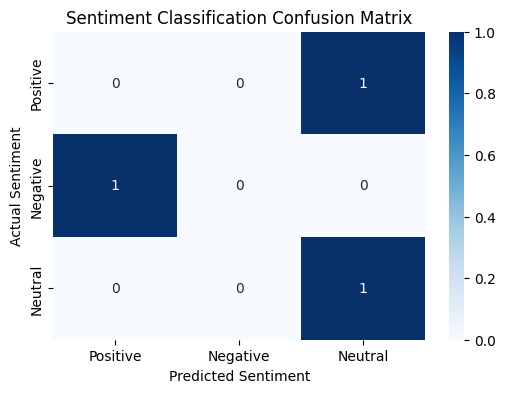

In [ ]:
# Create confusion matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['positive', 'negative', 'neutral']
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Positive', 'Negative', 'Neutral'],
    yticklabels=['Positive', 'Negative', 'Neutral']
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Sentiment Classification Confusion Matrix")

plt.show()

In [ ]:
def predict_sentiment(review):

    # Preprocess user text
    processed_review = preprocess_text(review)

    # Convert text into TF-IDF numbers
    review_tfidf = tfidf.transform([processed_review])

    # Predict sentiment
    prediction = model.predict(review_tfidf)

    return prediction[0]


# Test with your own reviews
review = "I really love this product"

result = predict_sentiment(review)

print("Your Review:", review)
print("Predicted Sentiment:", result)

Your Review: I really love this product
Predicted Sentiment: positive


In [ ]:
!pip install gradio

In [ ]:
import gradio as gr

def sentiment_interface(review):
    if not review.strip():
        return "Please enter a review."

    result = predict_sentiment(review)

    return "Predicted Sentiment: " + result.upper()


demo = gr.Interface(
    fn=sentiment_interface,
    inputs=gr.Textbox(
        lines=3,
        placeholder="Enter your review here..."
    ),
    outputs=gr.Textbox(label="Sentiment Result"),
    title="Intelligent Multi-Class Sentiment Classifier",
    description="Enter a review to predict whether its sentiment is Positive, Negative, or Neutral."
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://339770ad6314c34f61.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [20]:
!pip install datasets

In [21]:
from datasets import load_dataset

dataset = load_dataset(
    "Sp1786/multiclass-sentiment-analysis-dataset"
)

print(dataset)

README.md:   0%|          | 0.00/1.72k [00:00<?, ?B/s]

train_df.csv:   0%|          | 0.00/3.56M [00:00<?, ?B/s]

val_df.csv:   0%|          | 0.00/601k [00:00<?, ?B/s]

test_df.csv:   0%|          | 0.00/586k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/31232 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5205 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5206 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'label', 'sentiment'],
        num_rows: 31232
    })
    validation: Dataset({
        features: ['id', 'text', 'label', 'sentiment'],
        num_rows: 5205
    })
    test: Dataset({
        features: ['id', 'text', 'label', 'sentiment'],
        num_rows: 5206
    })
})


In [22]:
real_df = pd.DataFrame(dataset['train'])

print(real_df.head())
print("Dataset Shape:", real_df.shape)
print("Columns:", real_df.columns)

      id                                               text  label sentiment
0   9536                    Cooking microwave pizzas, yummy      2  positive
1   6135  Any plans of allowing sub tasks to show up in ...      1   neutral
2  17697   I love the humor, I just reworded it. Like sa...      2  positive
3  14182                       naw idk what ur talkin about      1   neutral
4  17840          That sucks to hear. I hate days like that      0  negative
Dataset Shape: (31232, 4)
Columns: Index(['id', 'text', 'label', 'sentiment'], dtype='object')


In [23]:
print("Dataset Columns:")
print(real_df.columns.tolist())

print("\nDataset Information:")
print(real_df.info())

print("\nFirst 5 Rows:")
print(real_df.head())

Dataset Columns:
['id', 'text', 'label', 'sentiment']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31232 entries, 0 to 31231
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         31232 non-null  int64 
 1   text       31232 non-null  object
 2   label      31232 non-null  int64 
 3   sentiment  31232 non-null  object
dtypes: int64(2), object(2)
memory usage: 976.1+ KB
None

First 5 Rows:
      id                                               text  label sentiment
0   9536                    Cooking microwave pizzas, yummy      2  positive
1   6135  Any plans of allowing sub tasks to show up in ...      1   neutral
2  17697   I love the humor, I just reworded it. Like sa...      2  positive
3  14182                       naw idk what ur talkin about      1   neutral
4  17840          That sucks to hear. I hate days like that      0  negative


In [24]:
print("Sentiment Categories:")
print(real_df['sentiment'].value_counts())

Sentiment Categories:
sentiment
neutral     11649
positive    10478
negative     9105
Name: count, dtype: int64


In [25]:
# Select required columns
real_df = real_df[['text', 'sentiment']].copy()

# Remove missing values
real_df = real_df.dropna()

# Remove empty reviews
real_df = real_df[real_df['text'].str.strip() != ""]

# Reset index
real_df = real_df.reset_index(drop=True)

print("Dataset prepared successfully!")
print("Total Reviews:", len(real_df))
print(real_df.head())

Dataset prepared successfully!
Total Reviews: 31232
                                                text sentiment
0                    Cooking microwave pizzas, yummy  positive
1  Any plans of allowing sub tasks to show up in ...   neutral
2   I love the humor, I just reworded it. Like sa...  positive
3                       naw idk what ur talkin about   neutral
4          That sucks to hear. I hate days like that  negative


In [26]:
real_df['clean_text'] = real_df['text'].apply(preprocess_text)

print(real_df[['text', 'clean_text', 'sentiment']].head())

                                                text  \
0                    Cooking microwave pizzas, yummy   
1  Any plans of allowing sub tasks to show up in ...   
2   I love the humor, I just reworded it. Like sa...   
3                       naw idk what ur talkin about   
4          That sucks to hear. I hate days like that   

                                          clean_text sentiment  
0                      cooking microwave pizza yummy  positive  
1                 plan allowing sub task show widget   neutral  
2  love humor reworded like saying therapy instea...  positive  
3                                  naw idk ur talkin   neutral  
4                            suck hear hate day like  negative  


In [27]:
# Use cleaned text as input
X = real_df['clean_text']

# Use sentiment as target
y = real_df['sentiment']

print("Features and labels prepared!")
print("Total reviews:", len(X))

print("\nSentiment categories:")
print(y.value_counts())

Features and labels prepared!
Total reviews: 31232

Sentiment categories:
sentiment
neutral     11649
positive    10478
negative     9105
Name: count, dtype: int64


In [28]:
# Preserve important negative words
stop_words = set(stopwords.words('english'))
stop_words = stop_words - {'not', 'no', 'nor', 'never'}

# Reprocess the real dataset
real_df['clean_text'] = real_df['text'].apply(preprocess_text)

print("Improved preprocessing completed!")
print(real_df[['text', 'clean_text']].head())

Improved preprocessing completed!
                                                text  \
0                    Cooking microwave pizzas, yummy   
1  Any plans of allowing sub tasks to show up in ...   
2   I love the humor, I just reworded it. Like sa...   
3                       naw idk what ur talkin about   
4          That sucks to hear. I hate days like that   

                                          clean_text  
0                      cooking microwave pizza yummy  
1                 plan allowing sub task show widget  
2  love humor reworded like saying therapy instea...  
3                                  naw idk ur talkin  
4                            suck hear hate day like  


In [29]:
X = real_df['clean_text']
y = real_df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

Training reviews: 24985
Testing reviews: 6247


In [30]:
tfidf = TfidfVectorizer(max_features=10000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

print("TF-IDF completed!")

Training shape: (24985, 10000)
Testing shape: (6247, 10000)
TF-IDF completed!


In [31]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

print("Final model trained successfully!")

Final model trained successfully!


In [32]:
y_pred = model.predict(X_test_tfidf)

print("Classification Report:")
print(classification_report(y_test, y_pred))

score = f1_score(y_test, y_pred, average='macro')

print("Macro F1-Score:", score)

Classification Report:
              precision    recall  f1-score   support

    negative       0.69      0.60      0.64      1821
     neutral       0.59      0.67      0.63      2330
    positive       0.75      0.72      0.73      2096

    accuracy                           0.67      6247
   macro avg       0.68      0.66      0.67      6247
weighted avg       0.67      0.67      0.67      6247

Macro F1-Score: 0.6669453687337835


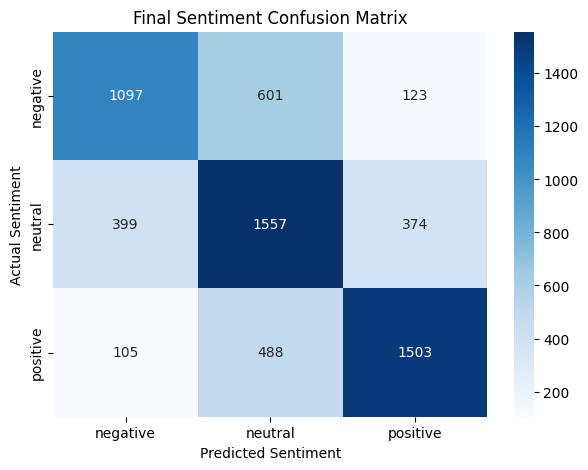

In [33]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Final Sentiment Confusion Matrix")

plt.show()

In [34]:
import gradio as gr

def sentiment_interface(review):

    if not review.strip():
        return "Please enter a review."

    # Preprocess user review
    processed_review = preprocess_text(review)

    # Convert into TF-IDF
    review_tfidf = tfidf.transform([processed_review])

    # Predict sentiment
    prediction = model.predict(review_tfidf)[0]

    # Get prediction probabilities
    probabilities = model.predict_proba(review_tfidf)[0]

    confidence = max(probabilities) * 100

    return (
        f"Predicted Sentiment: {prediction.upper()}\n"
        f"Confidence: {confidence:.2f}%"
    )


demo = gr.Interface(
    fn=sentiment_interface,
    inputs=gr.Textbox(
        lines=3,
        label="Enter Your Review",
        placeholder="Write your product or service review..."
    ),
    outputs=gr.Textbox(label="Sentiment Prediction"),
    title="Intelligent Multi-Class Sentiment Classifier",
    description="Analyze text reviews into Positive, Negative, or Neutral categories."
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c53b3d39ca89276dfc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
